<a href="https://colab.research.google.com/github/HSajeed/ROM/blob/main/ROM_pod_spod.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import os
import urllib.request

# URL to the official raw .mat file
url = "https://github.com/maziarraissi/PINNs/raw/master/main/Data/cylinder_nektar_wake.mat"
filename = "cylinder_nektar_wake.mat"

if not os.path.exists(filename):
    print(f"Downloading {filename}...")
    urllib.request.urlretrieve(url, filename)
    print("Download complete!")
else:
    print("File already exists.")

File already exists.


In [10]:
import random
import numpy as np
import scipy.io
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.optimizers import Adam

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)


In [11]:
# Load the file
data = scipy.io.loadmat('cylinder_nektar_wake.mat')

# Print keys and shapes
print("Keys in .mat file:", data.keys())

# Check the shape of the main velocity variable
print("\nShape of U_star:", data['U_star'].shape)
print("Shape of X_star:", data['X_star'].shape)
print("Shape of t:", data['t'].shape)

Keys in .mat file: dict_keys(['__header__', '__version__', '__globals__', 'X_star', 't', 'U_star', 'p_star'])

Shape of U_star: (5000, 2, 200)
Shape of X_star: (5000, 2)
Shape of t: (200, 1)


## Part 1: POD compression and LSTM forecast

### 1. Load the cylinder-wake data

In [12]:
# Extract exact shapes based on inspection
# Shape: (Space=5000, Comp=2, Time=200) -> We want (5000, 200)

X_all = data['U_star'][:, 0, :]
Coords = data['X_star']          # (x, y) coordinates for plotting

print(f"   Shape extracted: {X_all.shape} (Rows=Space, Cols=Time)")

   Shape extracted: (5000, 200) (Rows=Space, Cols=Time)


In [13]:
# 1. DATA LOADING (Benchmark Dataset)

def load_real_data():
    data = scipy.io.loadmat('cylinder_nektar_wake.mat')

    # U_star shape is (N_points, N_components, N_timesteps)
    # Use the streamwise component 'u' and keep (space, time) orientation.
    U_star = data['U_star']
    X_star = data['X_star']  # Spatial coordinates (x, y)
    t_star = data['t']       # Time

    U_data = U_star[:, 0, :]  # (N_points, N_timesteps)

    return U_data, X_star, t_star

print("Loading data...")
X_all, Coords, Time = load_real_data()
n_points, n_snapshots = X_all.shape
print(f"Loaded: {n_snapshots} snapshots with {n_points} spatial points each.")


Loading data...
Loaded: 200 snapshots with 5000 spatial points each.


### 2. POD via economy SVD

In [14]:
# --- 2. POD (COMPRESSION) ---

# X_all is (space, time); SVD expects (features x samples).
X_matrix = X_all

print("Computing SVD (Modes)...")
# U: Spatial Modes, S: Energy, VT: Temporal Dynamics
U, S, VT = np.linalg.svd(X_matrix, full_matrices=False)
V = VT.T

# Desired truncation rank, capped by the number of available singular values.
# For this dataset len(S)=200, so r=10.
r = min(10, len(S))

U_r = U[:, :r]      # The "Eigen-Wakes"
Sigma_r = np.diag(S[:r])
V_r = V[:, :r]      # The time coefficients to predict

# Visualization of Energy
energy = np.cumsum(S**2) / np.sum(S**2)
print(f"Top {r} modes capture {energy[r-1]*100:.4f}% of the flow energy.")


Computing SVD (Modes)...
Top 10 modes capture 99.9996% of the flow energy.


Diagnosing shapes...
U shape: (5000, 200)
VT shape: (200, 200)
>> Spatial modes are in U. Plotting U...


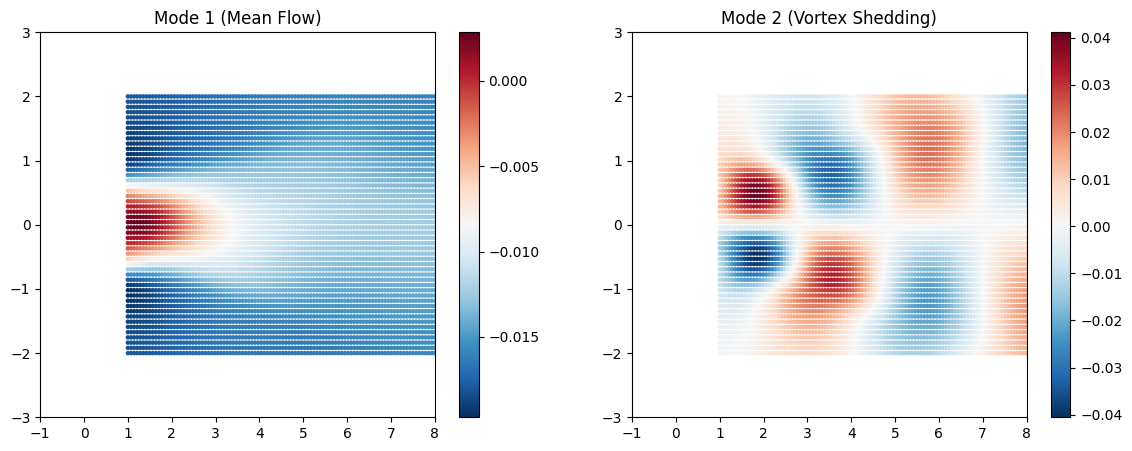

In [15]:
# --- ADAPTIVE VISUALIZATION ---
print("Diagnosing shapes...")
print(f"U shape: {U.shape}")
print(f"VT shape: {VT.shape}")

# LOGIC: Find which variable has 5000 rows (Space)
if U.shape[0] == 5000:
    print(">> Spatial modes are in U. Plotting U...")
    Modes = U
elif VT.shape[1] == 5000:
    print(">> Spatial modes are in VT. Plotting VT.T...")
    Modes = VT.T
else:
    raise ValueError("Could not find dimension 5000 in U or VT!")

# Now we plot 'Modes' which is guaranteed to be (5000, ...)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# POD modes are energy-ranked. The labels below are interpretive.
scat1 = ax1.scatter(Coords[:, 0], Coords[:, 1], c=Modes[:, 0], cmap='RdBu_r', s=5)
fig.colorbar(scat1, ax=ax1)
ax1.set_title("Mode 1 (Mean Flow)")
ax1.set_xlim([-1, 8]); ax1.set_ylim([-3, 3])

scat2 = ax2.scatter(Coords[:, 0], Coords[:, 1], c=Modes[:, 1], cmap='RdBu_r', s=5)
fig.colorbar(scat2, ax=ax2)
ax2.set_title("Mode 2 (Vortex Shedding)")
ax2.set_xlim([-1, 8]); ax2.set_ylim([-3, 3])

plt.show()


### 3. LSTM surrogate for POD coefficients

Training data shape: (200, 10) (should be 200 x 10)
Training LSTM...
Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - loss: 366.1540 - val_loss: 310.8206
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 281.4484 - val_loss: 250.4469
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 228.5343 - val_loss: 203.4604
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 183.8021 - val_loss: 161.9273
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 145.4641 - val_loss: 127.7469
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 114.1213 - val_loss: 99.9771
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 88.9794 - val_loss: 78.0804
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 68.8891 - val_loss: 60.5387
Epoch 9/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 53.0054 - val_loss: 46.7664
Epoch 10/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 40.7095 - val_loss: 36.1934
Epoch 11/100
10/10 ━━━━━━━━━━━━━━━━━━━━

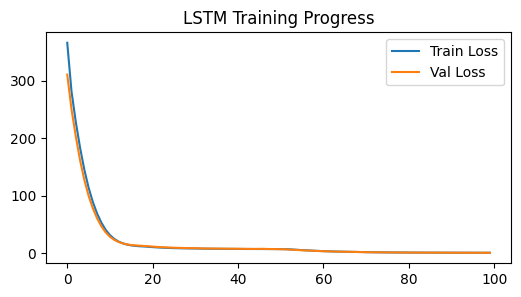

In [16]:
# --- 3. LSTM TRAINING ---

# time_coeffs = V_r @ Sigma_r, shape (200, r).
# Sigma is included here so the LSTM learns energy-weighted coefficients.
time_coeffs = V_r @ Sigma_r

print(f"Training data shape: {time_coeffs.shape} (should be 200 x {r})")

# 2. PREPARE SEQUENCES
lookback = 10
X_train_lstm = []
y_train_lstm = []

for i in range(len(time_coeffs) - lookback):
    X_train_lstm.append(time_coeffs[i:i+lookback])
    y_train_lstm.append(time_coeffs[i+lookback])

X_train_lstm = np.array(X_train_lstm)
y_train_lstm = np.array(y_train_lstm)

# 3. SPLIT
split = 150
x_tr, x_val = X_train_lstm[:split], X_train_lstm[split:]
y_tr, y_val = y_train_lstm[:split], y_train_lstm[split:]

# 4. MODEL
model = Sequential([
    LSTM(64, input_shape=(lookback, r), return_sequences=False),
    Dense(r)
])
model.compile(optimizer=Adam(learning_rate=0.01), loss='mse')

print("Training LSTM...")
history = model.fit(x_tr, y_tr, epochs=100, batch_size=16, verbose=1, validation_data=(x_val, y_val))
print("Model Trained.")

# Plot loss to check for overfitting
plt.figure(figsize=(6, 3))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title("LSTM Training Progress")
plt.show()

### 4. Autoregressive forecast and field reconstruction

In [17]:
# --- 4. PREDICTION & RECONSTRUCTION ---

# Autoregressive loop
current_batch = x_val[0].reshape(1, lookback, r)
predicted_coeffs = []

for i in range(len(x_val)):
    pred = model.predict(current_batch, verbose=0)[0]
    predicted_coeffs.append(pred)
    current_batch = np.append(current_batch[:, 1:, :], [[pred]], axis=1)

predicted_coeffs = np.array(predicted_coeffs)

# time_coeffs already includes Sigma, so x = U_r a (do not apply Sigma twice).
X_reconstructed = (U_r @ predicted_coeffs.T).T

# Field-level forecast error over the held-out horizon.
start_idx = split + lookback
truth_forecast = X_all[:, start_idx:start_idx + len(predicted_coeffs)].T
err_forecast = (
    np.linalg.norm(X_reconstructed - truth_forecast, axis=1)
    / np.linalg.norm(truth_forecast, axis=1)
)
print(f"Mean relative forecast error: {err_forecast.mean():.4f}")
print(f"Max relative forecast error:  {err_forecast.max():.4f}")


Mean relative forecast error: 0.1284
Max relative forecast error:  0.2932


### 5. Forecast animation

Generating forecast animation...
Done! GIF saved as 'pod_lstm_forecast.gif'


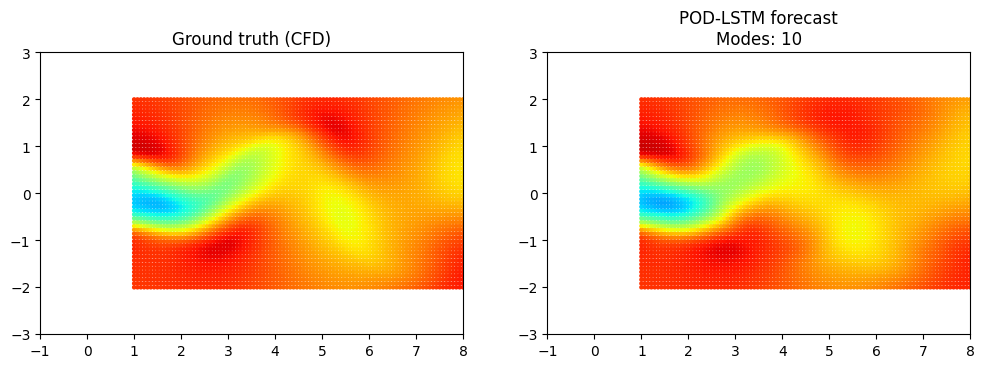

In [18]:
# --- 6. VISUALIZATION (GIF) ---
print("Generating forecast animation...")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Align timestamps: the first prediction corresponds to split + lookback.
# start_idx is defined in the prediction cell.

# 1. Ground Truth Plot
# X_all is (5000, 200), so we slice columns: X_all[:, index]
scat1 = ax1.scatter(Coords[:, 0], Coords[:, 1],
                    c=X_all[:, start_idx], cmap='jet', vmin=-1, vmax=1.5, s=5)
ax1.set_title("Ground truth (CFD)")
ax1.set_xlim([-1, 8]); ax1.set_ylim([-3, 3])
ax1.set_aspect('equal')

# 2. Prediction Plot
# X_reconstructed is (N_preds, 5000), so we slice rows: X_reconstructed[0, :]
scat2 = ax2.scatter(Coords[:, 0], Coords[:, 1],
                    c=X_reconstructed[0, :], cmap='jet', vmin=-1, vmax=1.5, s=5)
ax2.set_title(f"POD-LSTM forecast\nModes: {r}")
ax2.set_xlim([-1, 8]); ax2.set_ylim([-3, 3])
ax2.set_aspect('equal')

def update(frame):
    # Update Ground Truth (column slice)
    scat1.set_array(X_all[:, start_idx + frame])

    # Update Prediction (row slice)
    scat2.set_array(X_reconstructed[frame, :])
    return scat1, scat2

ani = animation.FuncAnimation(fig, update, frames=len(predicted_coeffs), blit=False)
ani.save('pod_lstm_forecast.gif', writer='pillow', fps=15)
print("Done! GIF saved as 'pod_lstm_forecast.gif'")

## Part 2: Sparse-sensor reconstruction

Part 1 compressed the field with POD and forecast the POD coefficients. This part asks a different question: given only a few point measurements of a snapshot, can we estimate the POD coefficients and reconstruct the full field?

For a measurement vector \(y = C a\), with \(C = U_r[\mathcal{S},:]\), the least-squares estimate is \(a = C^{+} y\). If the number of sensors \(p\) is at least the number of retained modes \(r\), and \(C\) has full column rank, the system is square or overdetermined. If \(p < r\), it is underdetermined and `pinv` returns the minimum-norm solution, which is not guaranteed to recover the true coefficients.

The next cells compare random sensor placement with QR-pivoted sensor placement, then sweep the number of sensors.

In [19]:
# --- 1. LOAD DATA & MODES ---

# Reload so Part 2 can run independently of Part 1.
data = scipy.io.loadmat('cylinder_nektar_wake.mat')
X_all = data['U_star'][:, 0, :]   # (5000, 200)
Coords = data['X_star']           # (5000, 2)
U, S, VT = np.linalg.svd(X_all, full_matrices=False)
r = min(10, len(S))
U_r = U[:, :r]

In [20]:
# --- 2. PLACE SENSORS ---
# Let's pick 5 random locations in the wake
# We use a fixed seed so we get the same sensors every time
np.random.seed(42)
n_sensors = 5

# Choose random indices from the 5000 available points
sensor_idx = np.random.choice(X_all.shape[0], n_sensors, replace=False)
sensor_locs = Coords[sensor_idx]

print(f"Placed {n_sensors} sensors at indices: {sensor_idx}")

Placed 5 sensors at indices: [1501 2586 2653 1055  705]


In [21]:
# --- 3. COMPUTE SENSOR MATRIX ---
# We extract the POD modes ONLY at the sensor locations
# Shape: (n_sensors, r) -> (5, 10)
C = U_r[sensor_idx, :]

# Pre-compute the Pseudo-Inverse: (C^T * C)^-1 * C^T
# This matrix converts "5 sensor readings" -> "10 mode coefficients"
Theta = np.linalg.pinv(C)

print(f"Reconstruction Matrix Shape: {Theta.shape}")

Reconstruction Matrix Shape: (10, 5)


In [22]:
# --- 4. RUN RECONSTRUCTION ---
# Reconstruct frame 159 from 5 random sensor measurements.
true_snapshot = X_all[:, 159]            # Full field (5000 points)
measurements = true_snapshot[sensor_idx] # Sensor readings (5 points)

# Estimate POD coefficients from sparse data
a_est = Theta @ measurements

# Reconstruct full field
X_sparse_rec = U_r @ a_est

err_sparse = np.linalg.norm(true_snapshot - X_sparse_rec) / np.linalg.norm(true_snapshot)
print(f"Relative reconstruction error with {n_sensors} random sensors: {err_sparse:.4f}")


Relative reconstruction error with 5 random sensors: 0.4031


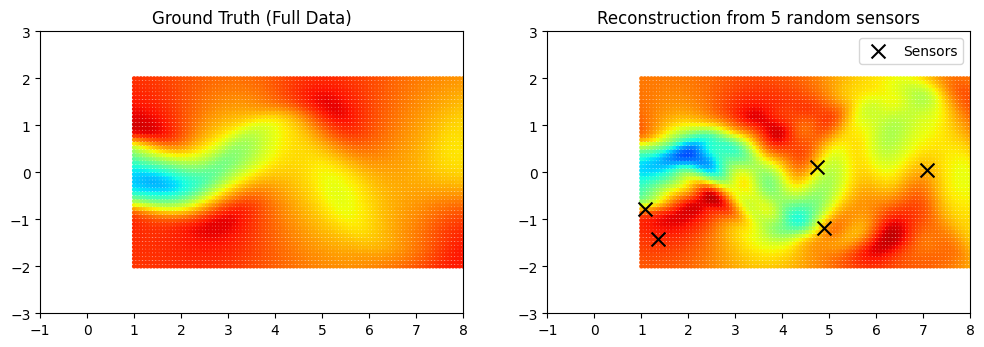

In [23]:
# --- 5. VISUALIZATION ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot True Field
scat1 = ax1.scatter(Coords[:,0], Coords[:,1], c=true_snapshot, cmap='jet', vmin=-1, vmax=1.5, s=5)
ax1.set_title("Ground Truth (Full Data)")
ax1.set_xlim([-1, 8]); ax1.set_ylim([-3, 3])
ax1.set_aspect('equal')

# Plot Reconstructed Field + Sensor Locations
scat2 = ax2.scatter(Coords[:,0], Coords[:,1], c=X_sparse_rec, cmap='jet', vmin=-1, vmax=1.5, s=5)
# Overlay the sensor positions as big black dots
ax2.scatter(sensor_locs[:,0], sensor_locs[:,1], c='black', s=100, marker='x', label='Sensors')
ax2.legend(loc='upper right')
ax2.set_title(f"Reconstruction from {n_sensors} random sensors")
ax2.set_xlim([-1, 8]); ax2.set_ylim([-3, 3])
ax2.set_aspect('equal')

plt.show()


### QR-pivoted sensor placement

Finding QR-pivoted sensor locations...
Indices of 10 QR-pivoted sensors: [2725 2325 2420 2831 3233 2021 1839 3539 1341 1930]
Relative reconstruction error with 10 QR-pivoted sensors: 2.273e-03


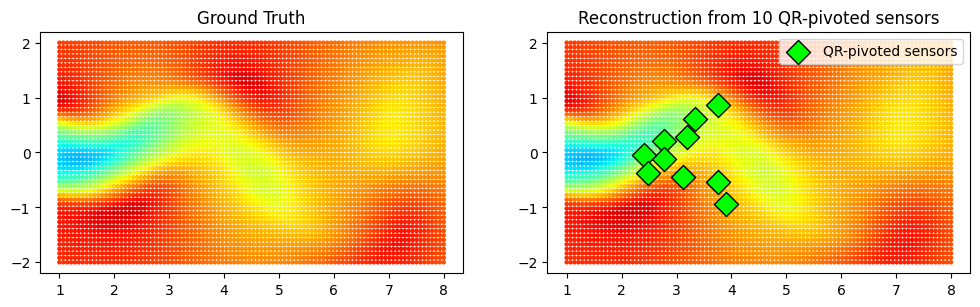

In [24]:
import scipy.linalg

# --- QR-PIVOTED SENSOR PLACEMENT ---
print("Finding QR-pivoted sensor locations...")

# Use the spatial POD modes U_r. QR with column pivoting on U_r.T
# orders spatial points by their pivoting importance.
Q, R, P = scipy.linalg.qr(U_r.T, pivoting=True)

# Use as many sensors as retained modes for a square sensor matrix.
s = r
sensor_indices = P[:s]
sensor_locs_qr = Coords[sensor_indices]

print(f"Indices of {s} QR-pivoted sensors: {sensor_indices}")

# --- RECONSTRUCTION WITH QR-PIVOTED SENSORS ---
C_opt = U_r[sensor_indices, :]
Theta_opt = np.linalg.pinv(C_opt)

measurements_opt = X_all[sensor_indices, 150]
a_opt = Theta_opt @ measurements_opt
X_smart_rec = U_r @ a_opt

err_smart = np.linalg.norm(X_all[:, 150] - X_smart_rec) / np.linalg.norm(X_all[:, 150])
print(f"Relative reconstruction error with {s} QR-pivoted sensors: {err_smart:.3e}")

# --- VISUALIZATION ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

scat1 = ax1.scatter(Coords[:,0], Coords[:,1], c=X_all[:, 150], cmap='jet', vmin=-1, vmax=1.5, s=5)
ax1.set_title("Ground Truth")
ax1.set_aspect('equal')

scat2 = ax2.scatter(Coords[:,0], Coords[:,1], c=X_smart_rec, cmap='jet', vmin=-1, vmax=1.5, s=5)
ax2.scatter(sensor_locs_qr[:,0], sensor_locs_qr[:,1], c='lime', s=150, marker='D', edgecolors='black', label='QR-pivoted sensors')
ax2.legend(loc='upper right')
ax2.set_title(f"Reconstruction from {s} QR-pivoted sensors")
ax2.set_aspect('equal')

plt.show()


### Sensor-count sweep

The sweep below reconstructs a single snapshot (frame 150) from \(p=1,\ldots,20\) QR-pivoted sensors. The error drops sharply once \(p \ge r\), because the sensor system changes from underdetermined to square/overdetermined. The residual error for \(p \ge r\) is the POD truncation error, not a sensor-placement limit.

Running sensor sweep (1 to 20)...
p= 9: relative error = 9.199e-01
p=10: relative error = 2.273e-03
p=20: relative error = 2.036e-03


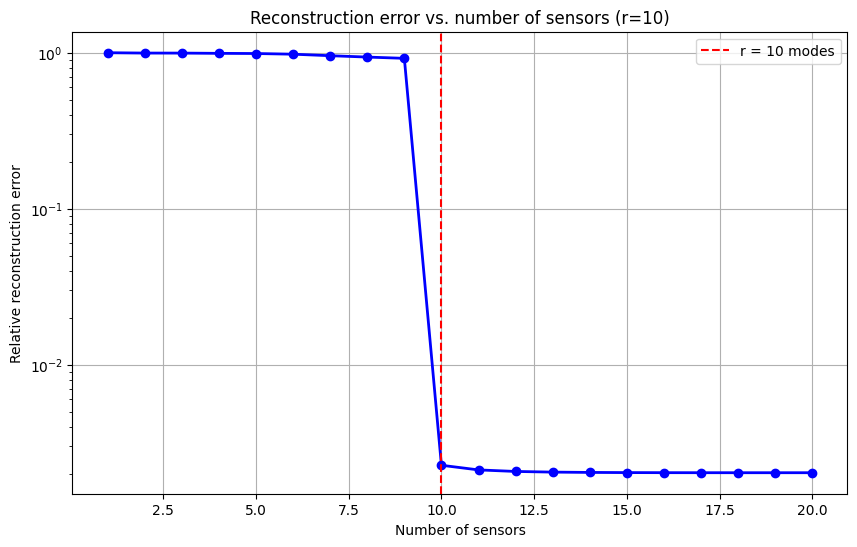

In [25]:
# --- SENSOR COUNT SWEEP ---
print("Running sensor sweep (1 to 20)...")

errors = []
sensor_counts = list(range(1, 21))
ground_truth = X_all[:, 150]  # Target frame

# Compute the QR pivoting order once.
Q, R, P = scipy.linalg.qr(U_r.T, pivoting=True)

for p in sensor_counts:
    current_indices = P[:p]
    C_p = U_r[current_indices, :]
    Theta_p = np.linalg.pinv(C_p)
    measurements = ground_truth[current_indices]
    a_est = Theta_p @ measurements
    X_rec = U_r @ a_est
    error = np.linalg.norm(ground_truth - X_rec) / np.linalg.norm(ground_truth)
    errors.append(error)

for p in [9, 10, 20]:
    print(f"p={p:2d}: relative error = {errors[p-1]:.3e}")

plt.figure(figsize=(10, 6))
plt.plot(sensor_counts, errors, 'bo-', linewidth=2)
plt.axvline(x=r, color='r', linestyle='--', label=f'r = {r} modes')
plt.title(f"Reconstruction error vs. number of sensors (r={r})")
plt.xlabel("Number of sensors")
plt.ylabel("Relative reconstruction error")
plt.grid(True)
plt.legend()
plt.yscale('log')
plt.show()


### Conditioning

For \(p < r\), the sensor matrix is underdetermined; the condition number alone does not explain the reconstruction error. The condition number is still useful for checking the numerical stability of the pseudoinverse for \(p \ge r\).

Checking sensor-matrix conditioning...


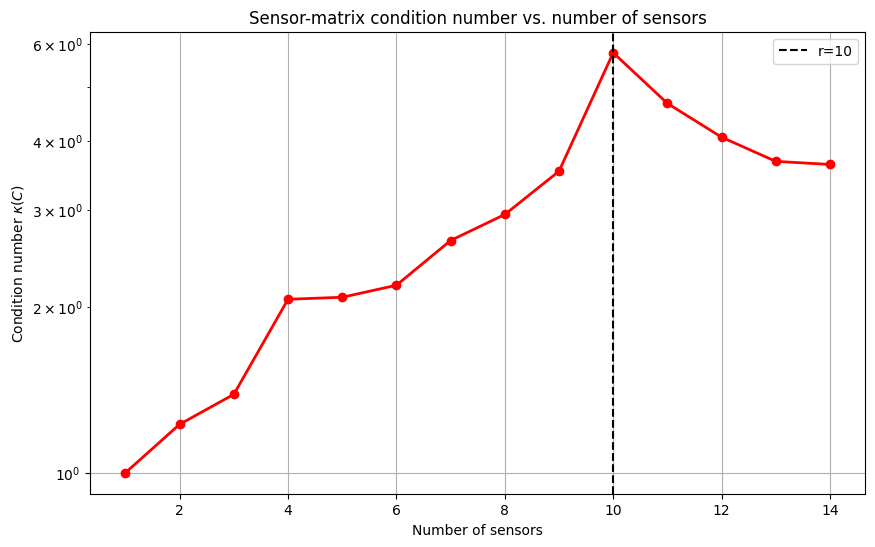

In [26]:
# --- SENSOR-MATRIX CONDITIONING ---
print("Checking sensor-matrix conditioning...")

cond_numbers = []
sensor_counts = list(range(1, 15))

Q, R, P = scipy.linalg.qr(U_r.T, pivoting=True)

for p in sensor_counts:
    current_indices = P[:p]
    C_p = U_r[current_indices, :]
    cond_numbers.append(np.linalg.cond(C_p))

plt.figure(figsize=(10, 6))
plt.plot(sensor_counts, cond_numbers, 'r-o', linewidth=2)
plt.axvline(x=r, color='k', linestyle='--', label=f'r={r}')
plt.yscale('log')
plt.title("Sensor-matrix condition number vs. number of sensors")
plt.xlabel("Number of sensors")
plt.ylabel(r"Condition number $\kappa(C)$")
plt.grid(True)
plt.legend()
plt.show()


## Summary

- POD with $r=10$ captures 99.9996% of the streamwise-velocity energy.
- The LSTM forecasts POD coefficients; field-level forecast errors are printed above.
- Sparse reconstruction is reliable only when $p \ge r$. QR pivoting is a greedy selection method, not a global optimum.
- SPOD is not implemented in this notebook; the current workflow is POD + LSTM.
- This notebook is a research prototype. See the repository README for scope, limitations, and reproducibility notes.